# A simple model for double descent

*Two models of double descent for weak features*, Mikhail Belkin, Daniel Hsu and Ji Xu, [arXiv:1903.07571](https://arxiv.org/abs/1903.07571)

We do a simulation study, and we compare that to the expected error, as computed in the paper.

(Code written by Leo.)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

n = 100
m = 40
beta = 1/np.sqrt(n)

nruns = 100
nsamples = 1000 # train + test

risk = []
var_beta = []
warr = range(1,n)
for w in warr:
    errs = np.zeros(nruns)
    var = np.zeros(nruns)
    for i in range(nruns):
        # data
        X = np.random.standard_normal((n,nsamples))
        y = beta*np.sum(X,axis=0)
        
        # train
        T = np.random.choice(np.arange(n),w,replace=False)
        W = range(w)
        X_tr = X[W,:m]
        y_tr = y[:m]
        # np.linalg.lstsq returns smallest norm solution in case there's an exact solution
        beta_fit,_,_,_ = np.linalg.lstsq(X_tr.T,y_tr)

        # test
        X_te = X[W,m:]
        y_te = y[m:]
        y_pr = np.inner(X_te.T, beta_fit)

        errs[i] = np.mean((y_te-y_pr)**2)
        var[i] = np.var(beta_fit)
    risk.append(np.mean(errs))
    var_beta.append(np.mean(var))

Text(0.5, 1.0, 'variance of $\\beta$')

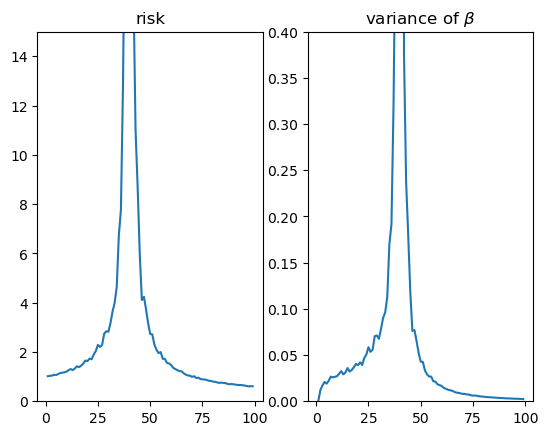

In [4]:
fig,axs = plt.subplots(1,2)
axs[0].plot(warr, risk)
axs[0].set_ylim((0,15))
axs[0].set_title('risk')
axs[1].plot(warr, var_beta)
axs[1].set_ylim((0,.4))
axs[1].set_title(r'variance of $\beta$')

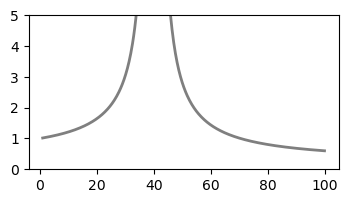

In [6]:
def make_fun(m,n):
    def fun(w):
        classical = lambda w : (n-w)/n*(1+w/(m-w-1))
        over = lambda w : 1+m/n*((n-m-1)/(w-m-1)-2)
        res = np.where(w<m-1, classical(w), np.inf)
        res = np.where(w>m+1, over(w), res)
        return res
    return fun

f=make_fun(m,n)

ww=np.linspace(1,n,500)
fig,ax=plt.subplots(figsize=(4,2))
ax.plot(ww,f(ww),linewidth=2,color="tab:grey")

ax.set_ylim(bottom=0,top=5)
plt.savefig("ddescent.png",dpi=300)

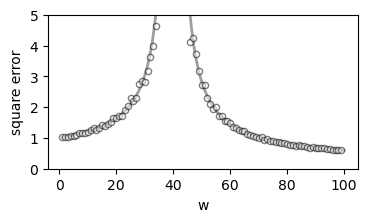

In [14]:
fig,ax=plt.subplots(figsize=(4,2))
ax.plot(ww,f(ww),linewidth=2,color="tab:grey",alpha=0.75)
ax.scatter(warr, risk,zorder=2,color="w",edgecolor="k",alpha=0.5,s=20)

ax.set_ylim(bottom=0,top=5)
ax.set_ylabel("square error")
ax.set_xlabel("w")
plt.savefig("ddescent.png",dpi=300)